# PSNR-IQA: от изображений до сабмита

По одному искажённому изображению предсказываем PSNR в дБ. Метрика — MAE, меньше лучше. Входные данные — файлы соревнования PSNR-IQA: PNG, train.csv и sample_submission.csv. Подключите [соревнование PSNR-IQA](https://www.kaggle.com/competitions/psnr-iqa) как Input, включите GPU и Internet On для официальных весов ImageNet из Keras. Локально укажите каталог распакованного датасета в PSNR_DATA_DIR.

Все вычисления выполняются в ячейках: 155 признаков из пикселей, пять групповых фолдов, три бустинга, две MLP, две EfficientNetB0, LightGBM-стекинг и CSV. Веса ImageNet — инициализация CNN, дообучение идёт на PSNR-IQA. На Kaggle используются установленные библиотеки. Локально нужны Python, Jupyter, NumPy, pandas, SciPy, scikit-image, OpenCV, scikit-learn, TensorFlow, Keras, LightGBM, XGBoost, CatBoost и Matplotlib.

Полный запуск занимает несколько часов и рассчитан на GPU. По умолчанию работает полный режим. Для проверки кода на небольшой выборке задайте PSNR_SMOKE=1 до запуска ядра. Он уменьшает число исходников и итераций, отключает скачивание весов и сохраняет результаты в отдельный каталог. Метрики этого режима служат только диагностике.

## Результаты полного запуска

Версия 3 выполнилась на Tesla T4 примерно за 8 ч 55 мин. Все признаки и модели рассчитаны из исходного PSNR-IQA. CV MAE подтверждена по 13 210 OOF-прогнозам. Файл из 3 310 строк оценён Kaggle после завершения соревнования.

| Прогон | CV MAE, дБ | Kaggle public | Kaggle private | Сабмит |
|---|---:|---:|---:|---:|
| Полный запуск ноутбука, v3 | **0,456034** | **0,41615** | **0,41949** | 58765896 |
| Исторический стекинг, прогон 11 | 0,450787 | 0,41641 | 0,41627 | 58445233 |

Из отдельных моделей в полном запуске лучше всего сработала EfficientNetB0 на целых кадрах, MAE 0,498874 дБ. Стекинг дал 0,456034 дБ. Прогнозы полного запуска имеют меньшую ошибку на public, а исторический прогон — на private. Это результаты двух запусков одного подхода.

Значения выше относятся к завершённой версии 3. При повторном обучении на GPU значения могут немного отличаться.


Выводы ячеек восстановлены из файлов и журнала выполненной версии 3: лог обучения, фолды, таблицы, три исходных PNG и первые строки отправленного CSV. Исходник скачан с Kaggle; код ячеек совпадает с проверенной версией.

In [1]:
import os
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

SMOKE = os.environ.get("PSNR_SMOKE") == "1"
KAGGLE = Path("/kaggle/working").is_dir()
root = Path(os.environ.get("PSNR_DATA_DIR", "/kaggle/input" if KAGGLE else "data"))
output = Path("/kaggle/working" if KAGGLE else "outputs") / ("psnr_smoke" if SMOKE else "psnr_solution")
output.mkdir(parents=True, exist_ok=True)
workers = min(4, os.cpu_count() or 1)
cv2.setNumThreads(1)
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
print(f"TensorFlow {tf.__version__}; Keras {keras.__version__}; GPU: {len(gpus)}; smoke: {SMOKE}")

TensorFlow 2.21.0; Keras 3.13.2; GPU: 2; smoke: False


## Данные и фолды

В полном наборе 13 210 размеченных изображений и 3 310 тестовых. По суффиксу имени выделяем исходник и вариант искажения. Исходник нужен для группировки фолдов, вариант — для итоговой диагностики. Оба исключаем из табличных признаков.

In [2]:
"""Загрузка и проверка меток соревнования PSNR-IQA."""
from pathlib import Path

import numpy as np
import pandas as pd

NAME_PATTERN = r"^(?P<source>.+)_(?P<variant>\d+)\.png$"
SERVICE_COLUMNS = ("source", "variant")


def add_name_parts(frame, id_column):
    """Добавляет столбцы исходника и типа искажения, разобрав имя файла.

    Эти столбцы нужны для группировки фолдов и разбивки ошибки, на вход модели они не подаются.
    """
    parts = frame[id_column].str.extract(NAME_PATTERN)
    invalid = frame.loc[parts["source"].isna(), id_column]
    if not invalid.empty:
        raise ValueError(f"Имена файлов не соответствуют шаблону: {invalid.head().tolist()}")
    return frame.assign(source=parts["source"], variant=parts["variant"])


def check_columns(frame, columns, name):
    """Проверяет наличие столбцов и отсутствие повторов в первом из них."""
    missing = [column for column in columns if column not in frame.columns]
    if missing:
        raise ValueError(f"В файле {name} нет столбцов: {missing}")
    if frame[columns[0]].duplicated().any():
        raise ValueError(f"В файле {name} есть повторяющиеся значения {columns[0]}")


def check_target(train, target):
    """Проверяет, что целевая переменная числовая и конечная."""
    values = pd.to_numeric(train[target], errors="coerce")
    if not np.isfinite(values).all():
        raise ValueError(f"Столбец {target} содержит пропуски или нечисловые значения")


def check_sources_disjoint(train, test):
    """Проверяет, что исходные изображения train и test не пересекаются."""
    shared = set(train["source"]) & set(test["source"])
    if shared:
        raise ValueError(f"Исходники встречаются и в train, и в test: {sorted(shared)[:5]}")


def load_data(data_config):
    """Загружает и проверяет train и test, добавляя служебные столбцы."""
    data_dir = Path(data_config["dir"])
    id_column = data_config["id_column"]
    target = data_config["target"]

    train = pd.read_csv(data_dir / data_config["train_file"])
    test = pd.read_csv(data_dir / data_config["test_file"])
    check_columns(train, [id_column, target], data_config["train_file"])
    check_columns(test, [id_column], data_config["test_file"])
    check_target(train, target)

    train = add_name_parts(train, id_column)
    test = add_name_parts(test, id_column)
    check_sources_disjoint(train, test)
    return train, test


def check_feature_table(table, names, id_column):
    """Проверяет, что таблица описывает все изображения и содержит только конечные значения."""
    check_columns(table, [id_column], "признаков")
    missing = set(names) - set(table[id_column])
    if missing:
        raise ValueError(f"В таблице признаков нет {len(missing)} изображений: {sorted(missing)[:5]}")
    values = table.drop(columns=id_column).to_numpy(dtype=np.float64)
    if not np.isfinite(values).all():
        raise ValueError("Таблица признаков содержит пропуски или бесконечные значения")


def attach_features(frame, table, id_column):
    """Добавляет признаки к таблице меток, сохраняя порядок её строк."""
    return frame.merge(table, on=id_column, how="left", validate="one_to_one")


def feature_columns(train, id_column, target):
    """Возвращает столбцы, которые подаются на вход модели."""
    excluded = {id_column, target, *SERVICE_COLUMNS}
    return [column for column in train.columns if column not in excluded]

In [3]:
"""Разбиение данных на фолды и оценка моделей по кросс-валидации."""
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold


def make_folds(train, target, n_splits, n_bins, seed, group=True):
    """Возвращает разбиения со стратификацией по бинам цели и группировкой по исходнику.

    Варианты одного исходника похожи между собой, а в test исходники из train не встречаются.
    Поэтому все варианты исходника должны попадать в один фолд. Разбиение без группировки
    (group=False) нужно только для сравнения: оно завышает качество моделей.
    """
    bins = pd.qcut(train[target], n_bins, labels=False, duplicates="drop")
    if not group:
        return list(StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(train, bins))
    splitter = StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed)
    return list(splitter.split(train, bins, train["source"]))

In [4]:
if (root / "train.csv").is_file() and (root / "sample_submission.csv").is_file():
    data_dir = root
else:
    candidates = sorted({p.parent for p in root.rglob("train.csv")
                         if (p.parent / "sample_submission.csv").is_file()})
    if len(candidates) != 1:
        raise ValueError(f"Ожидался один набор PSNR-IQA в {root}, найдено: {candidates}. Проверьте Input.")
    data_dir = candidates[0]

train, test = load_data({"dir": data_dir, "train_file": "train.csv", "test_file": "sample_submission.csv",
                         "id_column": "img_name", "target": "PSNR"})
if SMOKE:
    train_groups = train.source.drop_duplicates().sample(n=16, random_state=42)
    test_groups = test.source.drop_duplicates().sample(n=3, random_state=42)
    train = train[train.source.isin(train_groups)].reset_index(drop=True)
    test = test[test.source.isin(test_groups)].reset_index(drop=True)
elif (len(train), len(test)) != (13210, 3310):
    raise ValueError(f"Неожиданный размер набора: {(len(train), len(test))}")

folds = make_folds(train, "PSNR", n_splits=2 if SMOKE else 5, n_bins=4 if SMOKE else 10, seed=42)
fold_id = np.full(len(train), -1)
for number, (fit, valid) in enumerate(folds, start=1):
    if set(train.source.iloc[fit]) & set(train.source.iloc[valid]) or np.any(fold_id[valid] != -1):
        raise ValueError("Неверное разбиение исходников")
    fold_id[valid] = number
if np.any(fold_id == -1):
    raise ValueError("Не все строки получили проверочный фолд")

names = pd.concat([train.img_name, test.img_name], ignore_index=True)
wanted = set(names)
image_paths = {}
for image in data_dir.rglob("*.png"):
    if image.name in wanted:
        if image.name in image_paths:
            raise ValueError(f"Найдено несколько изображений {image.name}")
        image_paths[image.name] = str(image)
missing = wanted - image_paths.keys()
if missing:
    raise FileNotFoundError(f"Не найдено PNG: {len(missing)}, например {sorted(missing)[:5]}")
display(train.groupby(fold_id).agg(images=("img_name", "size"), sources=("source", "nunique"),
                                  median_psnr=("PSNR", "median")))

,images,sources,median_psnr
1,2640,528,28.076643
2,2645,529,28.053100
3,2645,529,28.052224
4,2640,528,28.045824
5,2640,528,28.075102


## 155 признаков из пикселей

Признаки описывают цвет, резкость, шум, блочность, спектр, статистики естественных сцен, текстуру и следы отдельных искажений. Строки рассчитываются независимо. Извлечение не использует PSNR и групповые метки. Семь значащих цифр повторяют формат таблицы в историческом эксперименте.

In [5]:
"""Извлечение признаков качества из изображений.

Каждому изображению соответствует одна строка таблицы. Признаки вычисляются только из пикселей
и описывают статистики цвета, резкость, шум, блочность, спектр, естественную статистику сцены,
текстуру и следы отдельных искажений: изменения уровней, шума и изменения размера.
"""
import os
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from scipy.fft import dctn
from scipy.special import gamma
from scipy.stats import kurtosis, skew
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

PROGRESS_STEP = 1000
IMAGE_TIMEOUT_SECONDS = 300
THREAD_LIMITS = {"OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1"}

EPS = 1e-8
SHARPNESS_SCALES = (1, 2, 4)
FLAT_GRADIENT = 2.0
REBLUR_SIZE = 9
IMPULSE_THRESHOLD = 40
BLOCK_PERIODS = (4, 8, 16, 32)
DCT_SIZE = 8
DCT_ZERO_THRESHOLD = 1.0
RADIAL_BINS = 8
NSS_SCALES = (1, 2)
GLCM_LEVELS = 64
GLCM_DISTANCES = (1, 2, 4)
GLCM_ANGLES = (0.0, np.pi / 2)
GLCM_PROPERTIES = ("contrast", "homogeneity", "energy", "correlation")
LBP_POINTS = 8
LBP_RADIUS = 1
GABOR_WAVELENGTHS = (4, 8, 16)
GABOR_ORIENTATIONS = (0.0, np.pi / 4, np.pi / 2, 3 * np.pi / 4)
GABOR_SIZE = 31
HISTOGRAM_PEAK_RATIO = 1.5
HAAR_MAD_SCALE = 0.6745
NOISE_SIGMA_FLOOR = 0.1
PSNR_PEAK = 255.0
# Пики спектра второй производной на частотах ниже этой дают объекты сцены, а не интерполяция.
RESAMPLE_MIN_FREQUENCY = 0.03
RESIZE_SCALES = (1.5, 2, 3, 4)

IMMERKAER_MASK = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], dtype=np.float32)
GGD_SHAPES = np.arange(0.2, 10.0, 0.01)
GGD_RATIOS = gamma(1 / GGD_SHAPES) * gamma(3 / GGD_SHAPES) / gamma(2 / GGD_SHAPES) ** 2


def build_gabor_bank():
    """Создаёт банк фильтров Габора с нулевой постоянной составляющей."""
    bank = {}
    for wavelength in GABOR_WAVELENGTHS:
        for index, theta in enumerate(GABOR_ORIENTATIONS):
            kernel = cv2.getGaborKernel(
                (GABOR_SIZE, GABOR_SIZE), 0.56 * wavelength, theta, wavelength, 0.5, 0, ktype=cv2.CV_32F
            )
            bank[(wavelength, index)] = kernel - kernel.mean()
    return bank


# Параллелизм задаётся пулом процессов, внутренние потоки OpenCV ему только мешали бы.
cv2.setNumThreads(1)
GABOR_BANK = build_gabor_bank()


def distribution_stats(prefix, values):
    """Возвращает основные статистики распределения значений."""
    flat = values.ravel()
    low, median, high = np.percentile(flat, [1, 50, 99])
    is_constant = flat.std() < EPS
    return {
        f"{prefix}_mean": float(flat.mean()),
        f"{prefix}_std": float(flat.std()),
        f"{prefix}_skew": 0.0 if is_constant else float(skew(flat)),
        f"{prefix}_kurt": 0.0 if is_constant else float(kurtosis(flat)),
        f"{prefix}_p01": float(low),
        f"{prefix}_p50": float(median),
        f"{prefix}_p99": float(high),
    }


def safe_correlation(first, second):
    """Считает корреляцию Пирсона; для постоянных каналов возвращает 1."""
    if first.std() < EPS or second.std() < EPS:
        return 1.0
    return float(np.corrcoef(first.ravel(), second.ravel())[0, 1])


def color_features(bgr):
    """Статистики каналов, связь между каналами и доля насыщенных пикселей."""
    blue, green, red = (bgr[:, :, index].astype(np.float32) for index in range(3))
    ycrcb = cv2.cvtColor(bgr, cv2.COLOR_BGR2YCrCb)
    features = {}
    for name, channel in (("red", red), ("green", green), ("blue", blue)):
        features.update(distribution_stats(f"color_{name}", channel))
    features.update(distribution_stats("color_luma", ycrcb[:, :, 0]))
    features.update(
        {
            "color_cr_std": float(ycrcb[:, :, 1].std()),
            "color_cb_std": float(ycrcb[:, :, 2].std()),
            "color_corr_rg": safe_correlation(red, green),
            "color_corr_gb": safe_correlation(green, blue),
            "color_corr_rb": safe_correlation(red, blue),
            "color_share_zero": float((bgr == 0).mean()),
            "color_share_full": float((bgr == 255).mean()),
        }
    )
    return features


def sharpness_at_scale(gray, scale):
    """Меры резкости изображения, уменьшенного в заданное число раз."""
    size = (gray.shape[1] // scale, gray.shape[0] // scale)
    image = gray if scale == 1 else cv2.resize(gray, size, interpolation=cv2.INTER_AREA)
    grad_x = cv2.Sobel(image, cv2.CV_32F, 1, 0)
    grad_y = cv2.Sobel(image, cv2.CV_32F, 0, 1)
    magnitude = np.hypot(grad_x, grad_y)
    p50, p90, p99 = np.percentile(magnitude, [50, 90, 99])
    prefix = f"sharp_s{scale}"
    return {
        f"{prefix}_laplacian_var": float(cv2.Laplacian(image, cv2.CV_32F).var()),
        f"{prefix}_tenengrad": float((grad_x**2 + grad_y**2).mean()),
        f"{prefix}_brenner": float(((image[:, 2:] - image[:, :-2]) ** 2).mean()),
        f"{prefix}_gradient_p50": float(p50),
        f"{prefix}_gradient_p90": float(p90),
        f"{prefix}_gradient_p99": float(p99),
        f"{prefix}_flat_share": float((magnitude < FLAT_GRADIENT).mean()),
    }


def reblur_ratio(gray, axis):
    """Мера размытия Crete: доля перепадов, которая сохраняется после повторного размытия."""
    kernel_size = (1, REBLUR_SIZE) if axis == 0 else (REBLUR_SIZE, 1)
    original = np.abs(np.diff(gray, axis=axis))
    blurred = np.abs(np.diff(cv2.blur(gray, kernel_size), axis=axis))
    lost = np.maximum(original - blurred, 0)
    return float((original.sum() - lost.sum()) / (original.sum() + EPS))


def sharpness_features(gray):
    """Резкость на нескольких масштабах и устойчивость к повторному размытию."""
    features = {}
    for scale in SHARPNESS_SCALES:
        features.update(sharpness_at_scale(gray, scale))
    features["sharp_reblur_vertical"] = reblur_ratio(gray, 0)
    features["sharp_reblur_horizontal"] = reblur_ratio(gray, 1)
    return features


def immerkaer_sigma(channel):
    """Оценка стандартного отклонения шума методом Immerkaer."""
    height, width = channel.shape
    response = np.abs(cv2.filter2D(channel, cv2.CV_32F, IMMERKAER_MASK))[1:-1, 1:-1]
    return float(np.sqrt(np.pi / 2) * response.sum() / (6 * (height - 2) * (width - 2)))


def split_blocks(image, size):
    """Разбивает изображение на неперекрывающиеся квадратные блоки."""
    rows = image.shape[0] // size
    columns = image.shape[1] // size
    cropped = image[: rows * size, : columns * size]
    return cropped.reshape(rows, size, columns, size).transpose(0, 2, 1, 3).reshape(-1, size, size)


def noise_features(bgr, gray):
    """Оценки шума по всему изображению, по каналам и в однородных областях."""
    median = cv2.medianBlur(bgr, 3)
    residual = np.abs(bgr.astype(np.float32) - median.astype(np.float32))
    block_std = split_blocks(gray, DCT_SIZE).std(axis=(1, 2))
    low, middle, high = np.percentile(block_std, [5, 50, 95])
    features = {
        "noise_immerkaer_gray": immerkaer_sigma(gray),
        "noise_median_residual_mean": float(residual.mean()),
        "noise_median_residual_p99": float(np.percentile(residual, 99)),
        "noise_impulse_share": float((residual > IMPULSE_THRESHOLD).mean()),
        "noise_block_std_p05": float(low),
        "noise_block_std_p50": float(middle),
        "noise_block_std_p95": float(high),
    }
    for index, name in enumerate(("blue", "green", "red")):
        features[f"noise_immerkaer_{name}"] = immerkaer_sigma(bgr[:, :, index].astype(np.float32))
    return features


def blockiness(gray, period, axis):
    """Отношение перепадов на границах блоков к перепадам внутри блоков."""
    profile = np.abs(np.diff(gray, axis=axis)).mean(axis=1 - axis)
    on_boundary = (np.arange(profile.size) + 1) % period == 0
    return float(profile[on_boundary].mean() / (profile[~on_boundary].mean() + EPS))


def compression_features(gray):
    """Блочность на нескольких периодах и распределение коэффициентов DCT."""
    features = {}
    for period in BLOCK_PERIODS:
        features[f"comp_block{period}_horizontal"] = blockiness(gray, period, 1)
        features[f"comp_block{period}_vertical"] = blockiness(gray, period, 0)

    coefficients = np.abs(dctn(split_blocks(gray, DCT_SIZE), axes=(1, 2), norm="ortho"))
    rows, columns = np.indices((DCT_SIZE, DCT_SIZE))
    frequency = rows + columns
    bands = {
        "low": (frequency > 0) & (frequency <= 4),
        "mid": (frequency > 4) & (frequency <= 9),
        "high": frequency > 9,
    }
    for name, mask in bands.items():
        selected = coefficients[:, mask]
        features[f"comp_dct_{name}_mean"] = float(selected.mean())
        features[f"comp_dct_{name}_zero_share"] = float((selected < DCT_ZERO_THRESHOLD).mean())
    return features


def spectral_features(gray):
    """Распределение энергии спектра по частотным кольцам и наклон спектра."""
    spectrum = np.abs(np.fft.rfft2(gray - gray.mean())) ** 2
    frequency_y = np.fft.fftfreq(gray.shape[0])[:, None]
    frequency_x = np.fft.rfftfreq(gray.shape[1])[None, :]
    radius = np.minimum(np.hypot(frequency_y, frequency_x) / 0.5, 1.0)
    bins = np.minimum((radius * RADIAL_BINS).astype(int), RADIAL_BINS - 1)
    energy = np.bincount(bins.ravel(), weights=spectrum.ravel(), minlength=RADIAL_BINS)
    counts = np.bincount(bins.ravel(), minlength=RADIAL_BINS)
    shares = energy / (energy.sum() + EPS)
    centers = (np.arange(RADIAL_BINS) + 0.5) / RADIAL_BINS
    slope = np.polyfit(np.log(centers), np.log(energy / counts + EPS), 1)[0]
    features = {f"spectrum_ring{index}_share": float(share) for index, share in enumerate(shares)}
    features["spectrum_slope"] = float(slope)
    return features


def ggd_shape(values):
    """Оценка параметра формы обобщённого нормального распределения методом моментов."""
    ratio = (values**2).mean() / (np.abs(values).mean() ** 2 + EPS)
    return float(GGD_SHAPES[np.argmin(np.abs(GGD_RATIOS - ratio))])


def nss_features(gray):
    """Статистики нормализованных яркостей (MSCN) в духе модели BRISQUE."""
    features = {}
    for scale in NSS_SCALES:
        size = (gray.shape[1] // scale, gray.shape[0] // scale)
        image = gray if scale == 1 else cv2.resize(gray, size, interpolation=cv2.INTER_AREA)
        mean = cv2.GaussianBlur(image, (7, 7), 7 / 6)
        variance = cv2.GaussianBlur(image**2, (7, 7), 7 / 6) - mean**2
        mscn = (image - mean) / (np.sqrt(np.abs(variance)) + 1)
        horizontal = mscn[:, :-1] * mscn[:, 1:]
        vertical = mscn[:-1, :] * mscn[1:, :]
        is_constant = mscn.std() < EPS
        prefix = f"nss_s{scale}"
        features.update(
            {
                f"{prefix}_shape": ggd_shape(mscn),
                f"{prefix}_var": float(mscn.var()),
                f"{prefix}_kurt": 0.0 if is_constant else float(kurtosis(mscn.ravel())),
                f"{prefix}_skew": 0.0 if is_constant else float(skew(mscn.ravel())),
                f"{prefix}_pair_horizontal_mean": float(horizontal.mean()),
                f"{prefix}_pair_horizontal_var": float(horizontal.var()),
                f"{prefix}_pair_vertical_mean": float(vertical.mean()),
                f"{prefix}_pair_vertical_var": float(vertical.var()),
            }
        )
    return features


def texture_features(gray):
    """Признаки GLCM, гистограмма LBP и энергия откликов фильтров Габора."""
    gray_u8 = np.clip(gray, 0, 255).astype(np.uint8)
    quantized = (gray_u8 // (256 // GLCM_LEVELS)).astype(np.uint8)
    matrix = graycomatrix(
        quantized, GLCM_DISTANCES, GLCM_ANGLES, levels=GLCM_LEVELS, symmetric=True, normed=True
    )
    features = {}
    for prop in GLCM_PROPERTIES:
        values = graycoprops(matrix, prop).mean(axis=1)
        for distance, value in zip(GLCM_DISTANCES, values):
            features[f"texture_glcm_{prop}_d{distance}"] = float(value)

    pattern = local_binary_pattern(gray_u8, LBP_POINTS, LBP_RADIUS, method="uniform")
    histogram = np.bincount(pattern.astype(int).ravel(), minlength=LBP_POINTS + 2) / pattern.size
    for index, share in enumerate(histogram):
        features[f"texture_lbp_{index}"] = float(share)

    for (wavelength, orientation), kernel in GABOR_BANK.items():
        response = cv2.filter2D(gray, cv2.CV_32F, kernel)
        features[f"texture_gabor_w{wavelength}_o{orientation}"] = float(np.abs(response).mean())
    return features


def histogram_features(bgr):
    """Следы табличного изменения уровней (контраст, яркость): пропуски и пики гистограммы каналов.

    Растяжение диапазона оставляет пустые уровни, сжатие сливает соседние уровни в пики,
    поэтому гистограмма становится зубчатой. У неискажённого кадра она гладкая.
    """
    empty, peaks, roughness, distinct = [], [], [], []
    for index in range(3):
        counts = np.bincount(bgr[:, :, index].ravel(), minlength=256).astype(np.float64)
        used = np.flatnonzero(counts)
        inner = counts[used[0]:used[-1] + 1]
        distinct.append(used.size / 256)
        if inner.size < 3:
            empty.append(0.0)
            peaks.append(0.0)
            roughness.append(0.0)
            continue
        neighbours = (inner[:-2] + inner[2:]) / 2
        empty.append(float((inner == 0).mean()))
        peaks.append(float((inner[1:-1] > HISTOGRAM_PEAK_RATIO * neighbours + 1).mean()))
        roughness.append(float(np.abs(inner[1:-1] - neighbours).sum() / inner.sum()))
    return {
        "dist_hist_empty": float(np.mean(empty)),
        "dist_hist_peaks": float(np.mean(peaks)),
        "dist_hist_roughness": float(np.mean(roughness)),
        "dist_distinct_share": float(np.mean(distinct)),
    }


def haar_noise_sigma(bgr):
    """Оценка σ шума по медиане модулей диагональных коэффициентов Хаара (оценка Донохо).

    σ оценивается в каждом канале и усредняется по квадратам, как ошибка в PSNR по RGB:
    в яркости независимый шум каналов ослабляется в 0,67 раза.
    """
    height, width = bgr.shape[0] // 2 * 2, bgr.shape[1] // 2 * 2
    image = bgr[:height, :width].astype(np.float32)
    diagonal = (image[0::2, 0::2] - image[0::2, 1::2] - image[1::2, 0::2] + image[1::2, 1::2]) / 2
    sigmas = np.median(np.abs(diagonal), axis=(0, 1)) / HAAR_MAD_SCALE
    return float(np.sqrt(np.mean(sigmas**2)))


def resampling_peak(gray, axis):
    """Частота и выраженность главного пика спектра профиля второй производной вдоль оси.

    Увеличение размера в s раз делает вторую производную периодической с периодом s пикселей.
    """
    profile = np.abs(np.diff(gray, n=2, axis=axis)).mean(axis=1 - axis)
    spectrum = np.abs(np.fft.rfft(profile - profile.mean()))
    frequencies = np.fft.rfftfreq(profile.size)
    band = frequencies >= RESAMPLE_MIN_FREQUENCY
    top = int(np.argmax(spectrum[band]))
    return float(frequencies[band][top]), float(spectrum[band][top] / (np.median(spectrum[band]) + EPS))


def psnr(first, second):
    """PSNR двух изображений в дБ; для совпадающих изображений ограничен сверху."""
    mse = float(np.mean((first - second) ** 2))
    return 20 * np.log10(PSNR_PEAK / np.sqrt(max(mse, NOISE_SIGMA_FLOOR**2)))


def distortion_features(bgr, gray):
    """Признаки, нацеленные на варианты, которые хуже всего описывались остальными группами.

    Изменение контраста — гистограмма; слабый шум — оценка σ и PSNR, который дал бы аддитивный шум
    с такой σ; уменьшение и обратное увеличение размера — периодичность второй производной и PSNR
    повторного уменьшения и увеличения: у уже уменьшенного изображения он выше.
    """
    sigma = haar_noise_sigma(bgr)
    features = {
        **histogram_features(bgr),
        "dist_noise_sigma": sigma,
        "dist_noise_psnr": 20 * np.log10(PSNR_PEAK / max(sigma, NOISE_SIGMA_FLOOR)),
    }
    for axis, name in ((1, "rows"), (0, "columns")):
        frequency, peak = resampling_peak(gray, axis)
        features[f"dist_resample_frequency_{name}"] = frequency
        features[f"dist_resample_peak_{name}"] = peak
    height, width = gray.shape
    for scale in RESIZE_SCALES:
        small = cv2.resize(gray, (round(width / scale), round(height / scale)), interpolation=cv2.INTER_AREA)
        restored = cv2.resize(small, (width, height), interpolation=cv2.INTER_LINEAR)
        features[f"dist_resize_psnr_s{scale}"] = psnr(gray, restored)
    return features


def image_features(bgr):
    """Считает все признаки для одного изображения в формате BGR."""
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
    return {
        **color_features(bgr),
        **sharpness_features(gray),
        **noise_features(bgr, gray),
        **compression_features(gray),
        **spectral_features(gray),
        **nss_features(gray),
        **texture_features(gray),
        **distortion_features(bgr, gray),
    }


def process_image(path_text):
    """Читает файл и считает его признаки.

    Файл читается через numpy, поскольку cv2.imread в Windows не открывает пути с не-ASCII символами.
    """
    bgr = cv2.imdecode(np.fromfile(path_text, dtype=np.uint8), cv2.IMREAD_COLOR)
    if bgr is None:
        raise ValueError(f"Не удалось прочитать изображение: {path_text}")
    return image_features(bgr)

In [6]:
def find_images(names, images_dir):
    'Получить пути из индекса, собранного при проверке входных данных.'
    return [image_paths[name] for name in names]

started = time.perf_counter()
rows = []
with ThreadPoolExecutor(max_workers=workers) as pool:
    for count, row in enumerate(pool.map(process_image, find_images(names, data_dir)), start=1):
        rows.append(row)
        if count % 1000 == 0:
            print(f"{count}/{len(names)} изображений, {time.perf_counter() - started:.0f} с", flush=True)
features = pd.DataFrame(rows)
if features.shape[1] != 155:
    raise ValueError(f"Ожидалось 155 признаков, получено {features.shape[1]}")
features.insert(0, "img_name", names)
check_feature_table(features, names, "img_name")
feature_path = output / "features.csv.gz"
features.to_csv(feature_path, index=False, float_format="%.7g")
features = pd.read_csv(feature_path)
train = attach_features(train, features, "img_name")
test = attach_features(test, features, "img_name")
columns = feature_columns(train, "img_name", "PSNR")
assert len(columns) == 155 and len(features) == len(names)
print(f"{len(features)} изображений × {len(columns)} признаков")
display(features.head(3).iloc[:, :9])

1000/16520 изображений, 157 с
2000/16520 изображений, 313 с
3000/16520 изображений, 467 с
4000/16520 изображений, 621 с
5000/16520 изображений, 775 с
6000/16520 изображений, 928 с
7000/16520 изображений, 1083 с
8000/16520 изображений, 1237 с
9000/16520 изображений, 1390 с
10000/16520 изображений, 1544 с
11000/16520 изображений, 1699 с
12000/16520 изображений, 1855 с
13000/16520 изображений, 2011 с
14000/16520 изображений, 2169 с
15000/16520 изображений, 2327 с
16000/16520 изображений, 2484 с
16520 изображений × 155 признаков


,img_name,color_red_mean,color_red_std,color_red_skew,color_red_kurt,color_red_p01,color_red_p50,color_red_p99,color_green_mean
0,100083_1.png,137.1721,34.56944,-0.582441,-0.131625,47,142,196,131.1364
1,100083_2.png,137.0845,69.91911,-0.154059,-0.780960,0,140,255,131.2997
2,100083_3.png,136.9083,45.79963,-0.717786,0.227416,7,145,217,130.6361


## Базовые модели

Бустинги и MLP обучаются на 155 признаках. Ограничение выбросов и масштабирование MLP подбираются внутри обучающей части каждого фолда. EfficientNetB0 работают на пикселях. Одна CNN обучается на полных кадрах, другая — на вырезках 256 × 256. Для прогнозирования обе получают полный кадр.

In [7]:
"""Шаги предобработки признаков, которые обучаются на обучающей части фолда."""
import numpy as np
from scipy.stats import rankdata
from sklearn.base import BaseEstimator, TransformerMixin


class QuantileClipper(TransformerMixin, BaseEstimator):
    """Ограничивает каждый признак квантилями, посчитанными на обучающих данных."""

    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, features, target=None):
        self.bounds_ = np.quantile(np.asarray(features, dtype=float), [self.lower, self.upper], axis=0)
        return self

    def transform(self, features):
        return np.clip(np.asarray(features, dtype=float), *self.bounds_)


class CorrelationFilter(TransformerMixin, BaseEstimator):
    """Оставляет признаки, у которых модуль корреляции Спирмена с ранее оставленными не выше порога.

    Признаки просматриваются по порядку, поэтому из группы связанных остаётся первый.
    Постоянный признак даёт неопределённую корреляцию и отбрасывается.
    """

    def __init__(self, threshold=0.95):
        self.threshold = threshold

    def fit(self, features, target=None):
        ranks = rankdata(np.asarray(features, dtype=float), axis=0)
        with np.errstate(invalid="ignore", divide="ignore"):
            correlation = np.abs(np.corrcoef(ranks, rowvar=False))
        keep = []
        for column in range(correlation.shape[0]):
            if not np.isfinite(correlation[column, column]):
                continue
            if all(correlation[column, kept] <= self.threshold for kept in keep):
                keep.append(column)
        self.keep_ = np.array(keep)
        return self

    def transform(self, features):
        return np.asarray(features, dtype=float)[:, self.keep_]

In [8]:
"""Полносвязная нейросеть на Keras с интерфейсом модели scikit-learn."""
import os

import numpy as np
from sklearn.base import BaseEstimator, RegressorMixin

# Служебные сообщения TensorFlow о процессоре и оптимизациях не относятся к обучению модели.
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

SGD_MOMENTUM = 0.9


def make_optimizer(name, learning_rate):
    """Создаёт оптимизатор Keras по имени: adam, adamw, rmsprop или sgd (с моментом 0,9)."""
    import keras

    optimizers = {
        "adam": lambda: keras.optimizers.Adam(learning_rate),
        "adamw": lambda: keras.optimizers.AdamW(learning_rate),
        "rmsprop": lambda: keras.optimizers.RMSprop(learning_rate),
        "sgd": lambda: keras.optimizers.SGD(learning_rate, momentum=SGD_MOMENTUM),
    }
    if name not in optimizers:
        raise ValueError(f"Неизвестный оптимизатор {name}, доступны: {sorted(optimizers)}")
    return optimizers[name]()


def learning_rate_schedule(learning_rate, scheduler, steps):
    """Постоянный шаг обучения или косинусное уменьшение от learning_rate до нуля за steps шагов."""
    import keras

    if scheduler not in (None, "cosine"):
        raise ValueError(f"Неизвестный scheduler {scheduler}, доступны: None, cosine")
    return keras.optimizers.schedules.CosineDecay(learning_rate, steps) if scheduler == "cosine" else learning_rate


def train_network(model, batches, loss, optimizer, epochs):
    """Обучает сеть на наборе мини-батчей заданное число эпох.

    Цикл обучения написан явно вместо model.fit: в Keras 3.13 model.fit на каждом шаге переводит
    значения метрик в numpy способом, устаревшим для numpy 2, и выдаёт предупреждение.
    """
    import keras
    import tensorflow as tf

    loss_function = keras.losses.get(loss)
    # Оптимизатор создаёт свои переменные до трассировки шага: иначе LossScaleOptimizer запишет в граф
    # начальный множитель потерь вместо текущего.
    optimizer.build(model.trainable_variables)

    # Без XLA-компиляции: она удерживает память процесса для каждой модели, а моделей обучаются сотни.
    # AutoGraph не нужен: в шаге нет ветвлений и циклов Python.
    @tf.function(jit_compile=False, autograph=False)
    def train_step(inputs, target):
        with tf.GradientTape() as tape:
            value = optimizer.scale_loss(tf.reduce_mean(loss_function(target, model(inputs, training=True))))
        gradients = tape.gradient(value, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))

    for _ in range(epochs):
        for inputs, target in batches:
            train_step(inputs, target)


def build_network(n_features, hidden_units, activation, batch_norm, dropout):
    """Собирает сеть: скрытые слои, после каждого — батч-нормализация, активация и dropout, затем выход."""
    import keras

    layers = [keras.Input((n_features,))]
    for units in hidden_units:
        layers.append(keras.layers.Dense(units, use_bias=not batch_norm))
        if batch_norm:
            layers.append(keras.layers.BatchNormalization())
        layers.append(keras.layers.Activation(activation))
        if dropout:
            layers.append(keras.layers.Dropout(dropout))
    layers.append(keras.layers.Dense(1))
    return keras.Sequential(layers)


class MLPRegressor(BaseEstimator, RegressorMixin):
    """Многослойный перцептрон для регрессии.

    hidden_units — размеры скрытых слоёв. Целевая переменная стандартизуется по обучающей выборке,
    а прогноз переводится обратно в дБ: так начальные веса подходят для любого масштаба цели.
    scheduler="cosine" уменьшает шаг обучения по косинусу от learning_rate до нуля за всё обучение,
    scheduler=None оставляет его постоянным. loss — функция потерь Keras: mae, mse или huber.
    """

    def __init__(self, hidden_units=(128,), activation="relu", batch_norm=False, dropout=0.0, optimizer="adam",
                 learning_rate=1e-3, scheduler=None, batch_size=256, epochs=100, loss="mae", random_state=0):
        self.hidden_units = hidden_units
        self.activation = activation
        self.batch_norm = batch_norm
        self.dropout = dropout
        self.optimizer = optimizer
        self.learning_rate = learning_rate
        self.scheduler = scheduler
        self.batch_size = batch_size
        self.epochs = epochs
        self.loss = loss
        self.random_state = random_state

    def fit(self, X, y):
        """Обучает сеть мини-батчами, перемешивая обучающую выборку в каждой эпохе."""
        import keras
        import tensorflow as tf

        keras.utils.set_random_seed(self.random_state)
        features = np.asarray(X, dtype="float32")
        target = np.asarray(y, dtype="float32")
        self.target_mean_, self.target_std_ = float(target.mean()), float(target.std())
        scaled = ((target - self.target_mean_) / self.target_std_).reshape(-1, 1)

        steps = int(np.ceil(len(features) / self.batch_size)) * self.epochs
        optimizer = make_optimizer(self.optimizer, learning_rate_schedule(self.learning_rate, self.scheduler, steps))
        self.model_ = build_network(features.shape[1], self.hidden_units, self.activation, self.batch_norm,
                                    self.dropout)
        batches = (tf.data.Dataset.from_tensor_slices((features, scaled))
                   .shuffle(len(features), seed=self.random_state).batch(self.batch_size))
        train_network(self.model_, batches, self.loss, optimizer, self.epochs)
        return self

    def predict(self, X):
        scaled = self.model_(np.asarray(X, dtype="float32"), training=False).numpy()
        return scaled[:, 0] * self.target_std_ + self.target_mean_

In [9]:
"""Свёрточная нейросеть, которая предсказывает PSNR по самому изображению, с интерфейсом модели scikit-learn."""
import numpy as np
from sklearn.base import BaseEstimator, RegressorMixin


PREDICT_BATCH_SIZE = 8


def read_image(path):
    """Читает PNG в тензор float32 со значениями 0–255. AutoGraph не нужен: в функции нет ветвлений."""
    import tensorflow as tf

    return tf.cast(tf.io.decode_png(tf.io.read_file(path), channels=3), tf.float32)


def output_layer():
    """Выход регрессии всегда в float32: при смешанной точности float16 огрубил бы прогноз."""
    import keras

    return keras.layers.Dense(1, dtype="float32")


def build_small_cnn(filters):
    """Свёрточная сеть с нуля: в каждом блоке две свёртки 3×3 с батч-нормализацией и ReLU,
    затем уменьшение размера вдвое; после блоков — усреднение по всему изображению и выход."""
    import keras

    layers = [keras.Input((None, None, 3)), keras.layers.Rescaling(1 / 255)]
    for count in filters:
        for _ in range(2):
            layers += [keras.layers.Conv2D(count, 3, padding="same", use_bias=False),
                       keras.layers.BatchNormalization(), keras.layers.Activation("relu")]
        layers.append(keras.layers.MaxPooling2D())
    layers += [keras.layers.GlobalAveragePooling2D(), output_layer()]
    return keras.Sequential(layers)


def build_efficientnet(pretrained):
    """EfficientNetB0 без классификатора, с весами ImageNet или случайными, и выходом для регрессии."""
    import keras

    backbone = keras.applications.EfficientNetB0(include_top=False, weights="imagenet" if pretrained else None,
                                                 input_shape=(None, None, 3), pooling="avg")
    return keras.Sequential([backbone, output_layer()])


class ImageCNNRegressor(BaseEstimator, RegressorMixin):
    """Свёрточная сеть на изображениях в исходном разрешении.

    На вход подаются имена файлов изображений, сами изображения читаются из images_dir. Изображения
    не уменьшаются: уменьшение стёрло бы размытие, шум и следы сжатия, по которым
    оценивается PSNR. Сеть заканчивается усреднением по всему изображению, поэтому принимает любой
    размер. backbone="small" — сеть с нуля из блоков с числом фильтров filters, backbone="efficientnetb0" —
    EfficientNetB0, при pretrained=True с весами, обученными на ImageNet. При flips=True обучающие
    изображения случайно отражаются по горизонтали и вертикали: это не меняет PSNR. Если задан
    crop=(высота, ширина), сеть обучается на случайных вырезках этого размера, а прогноз делает по целому
    изображению. При mixed_precision=True вычисления идут во float16 с масштабированием потерь, а веса
    хранятся во float32. Целевая переменная стандартизуется, как в MLPRegressor.
    """

    def __init__(self, images_dir="data", backbone="small", filters=(32, 64, 128, 256), pretrained=True,
                 optimizer="adamw", learning_rate=3e-4, scheduler="cosine", batch_size=16, epochs=10, loss="mae",
                 flips=True, crop=None, mixed_precision=False, random_state=0):
        self.images_dir = images_dir
        self.backbone = backbone
        self.filters = filters
        self.pretrained = pretrained
        self.optimizer = optimizer
        self.learning_rate = learning_rate
        self.scheduler = scheduler
        self.batch_size = batch_size
        self.epochs = epochs
        self.loss = loss
        self.flips = flips
        self.crop = crop
        self.mixed_precision = mixed_precision
        self.random_state = random_state

    def _paths(self, X):
        """Пути к изображениям в порядке имён из X."""
        return find_images(np.asarray(X).ravel().tolist(), self.images_dir)

    def _build(self):
        """Собирает сеть; политика точности задаётся только на время сборки, чтобы не влиять на другие модели."""
        import keras

        builders = {"small": lambda: build_small_cnn(self.filters),
                    "efficientnetb0": lambda: build_efficientnet(self.pretrained)}
        if self.backbone not in builders:
            raise ValueError(f"Неизвестная архитектура {self.backbone}, доступны: {sorted(builders)}")
        previous = keras.config.dtype_policy()
        keras.config.set_dtype_policy("mixed_float16" if self.mixed_precision else "float32")
        try:
            return builders[self.backbone]()
        finally:
            keras.config.set_dtype_policy(previous)

    def fit(self, X, y):
        """Обучает сеть на мини-батчах изображений, перемешивая их в каждой эпохе."""
        import keras
        import tensorflow as tf

        keras.utils.set_random_seed(self.random_state)
        self.model_ = self._build()
        target = np.asarray(y, dtype="float32")
        self.target_mean_, self.target_std_ = float(target.mean()), float(target.std())
        scaled = ((target - self.target_mean_) / self.target_std_).reshape(-1, 1)

        def load(path, value):
            image = read_image(path)
            if self.crop is not None:
                image = tf.image.random_crop(image, (*self.crop, 3))
            if self.flips:
                image = tf.image.random_flip_up_down(tf.image.random_flip_left_right(image))
            return image, value

        # Перемешиваются пути, а изображения читаются уже после: буфер перемешивания из раскодированных
        # изображений занял бы десятки гигабайт памяти.
        batches = (tf.data.Dataset.from_tensor_slices((self._paths(X), scaled))
                   .shuffle(len(target), seed=self.random_state)
                   .map(tf.autograph.experimental.do_not_convert(load), num_parallel_calls=tf.data.AUTOTUNE)
                   .batch(self.batch_size).prefetch(tf.data.AUTOTUNE))

        steps = int(np.ceil(len(target) / self.batch_size)) * self.epochs
        optimizer = make_optimizer(self.optimizer, learning_rate_schedule(self.learning_rate, self.scheduler, steps))
        if self.mixed_precision:
            # Без масштабирования малые градиенты во float16 обращаются в ноль.
            optimizer = keras.optimizers.LossScaleOptimizer(optimizer)
        train_network(self.model_, batches, self.loss, optimizer, self.epochs)
        return self

    def predict(self, X):
        import tensorflow as tf

        batches = (tf.data.Dataset.from_tensor_slices(self._paths(X))
                   .map(tf.autograph.experimental.do_not_convert(read_image), num_parallel_calls=tf.data.AUTOTUNE)
                   .batch(PREDICT_BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
        scaled = np.concatenate([self.model_(batch, training=False).numpy()[:, 0] for batch in batches])
        return scaled * self.target_std_ + self.target_mean_

In [10]:
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

BASE_SPECS = {'lightgbm': {'type': 'lightgbm',
              'params': {'objective': 'l1',
                         'num_leaves': 63,
                         'n_estimators': 2000,
                         'learning_rate': 0.02,
                         'subsample': 0.8,
                         'subsample_freq': 1,
                         'colsample_bytree': 0.7,
                         'random_state': 0,
                         'n_jobs': -1,
                         'verbose': -1}},
 'xgboost': {'type': 'xgboost',
             'center_target': True,
             'params': {'objective': 'reg:absoluteerror',
                        'max_depth': 8,
                        'n_estimators': 2000,
                        'learning_rate': 0.02,
                        'subsample': 0.8,
                        'colsample_bytree': 0.7,
                        'tree_method': 'hist',
                        'random_state': 0,
                        'n_jobs': -1}},
 'catboost': {'type': 'catboost',
              'center_target': True,
              'params': {'loss_function': 'MAE',
                         'depth': 6,
                         'iterations': 2000,
                         'learning_rate': 0.05,
                         'random_seed': 0,
                         'thread_count': -1,
                         'verbose': 0,
                         'allow_writing_files': False}},
 'mlp_silu': {'type': 'mlp',
              'clip': [0.001, 0.999],
              'scaler': 'standard',
              'params': {'hidden_units': [256, 128, 64],
                         'activation': 'silu',
                         'batch_norm': True,
                         'dropout': 0.2,
                         'optimizer': 'adam',
                         'learning_rate': 0.001,
                         'scheduler': 'cosine',
                         'batch_size': 256,
                         'epochs': 100,
                         'loss': 'mae',
                         'random_state': 0}},
 'mlp_elu': {'type': 'mlp',
             'clip': [0.001, 0.999],
             'scaler': 'standard',
             'params': {'hidden_units': [256, 128, 64],
                        'activation': 'elu',
                        'batch_norm': True,
                        'dropout': 0.1,
                        'optimizer': 'adam',
                        'learning_rate': 0.001,
                        'scheduler': 'cosine',
                        'batch_size': 256,
                        'epochs': 100,
                        'loss': 'mae',
                        'random_state': 0}},
 'cnn_efficientnet': {'type': 'cnn',
                      'params': {'backbone': 'efficientnetb0',
                                 'pretrained': True,
                                 'optimizer': 'adamw',
                                 'learning_rate': 0.0003,
                                 'scheduler': 'cosine',
                                 'batch_size': 16,
                                 'epochs': 8,
                                 'loss': 'mae',
                                 'flips': True,
                                 'mixed_precision': True,
                                 'random_state': 0}},
 'cnn_efficientnet_crop': {'type': 'cnn',
                           'params': {'backbone': 'efficientnetb0',
                                      'pretrained': True,
                                      'optimizer': 'adamw',
                                      'learning_rate': 0.0003,
                                      'scheduler': 'cosine',
                                      'batch_size': 32,
                                      'epochs': 8,
                                      'loss': 'mae',
                                      'flips': True,
                                      'mixed_precision': True,
                                      'random_state': 0,
                                      'crop': [256, 256]}}}

STACK_PARAMS = {'objective': 'l1',
 'n_estimators': 1000,
 'learning_rate': 0.02,
 'num_leaves': 15,
 'min_child_samples': 50,
 'subsample': 0.8,
 'subsample_freq': 1,
 'colsample_bytree': 0.7,
 'random_state': 0,
 'n_jobs': -1,
 'verbose': -1}

In [11]:
constructors = {"lightgbm": LGBMRegressor, "xgboost": XGBRegressor, "catboost": CatBoostRegressor,
                "mlp": MLPRegressor, "cnn": ImageCNNRegressor}


def make_base_model(spec):
    'Обучаемые преобразования входят в конвейер конкретного фолда.'
    kind = spec["type"]
    params = dict(spec["params"])
    for key in ("n_jobs", "thread_count"):
        if key in params:
            params[key] = workers
    if kind == "cnn":
        params.update(images_dir=str(data_dir), mixed_precision=bool(gpus), pretrained=not SMOKE)
    if SMOKE:
        for key, value in {"n_estimators": 4, "iterations": 4, "epochs": 1}.items():
            if key in params:
                params[key] = value
        if kind == "lightgbm":
            params["min_child_samples"] = 5
    model = constructors[kind](**params)
    if spec.get("center_target"):
        model = TransformedTargetRegressor(model, transformer=StandardScaler(with_std=False))
    if "clip" in spec:
        model = make_pipeline(QuantileClipper(*spec["clip"]), StandardScaler(), model)
    return model


def fit_oof(name, factory, x_train, x_test, y, uses_keras=False):
    'Собирает прогнозы проверочных частей и средний прогноз на test.'
    predictions = np.full(len(y), np.nan)
    tests = []
    for n, (fit, valid) in enumerate(folds, start=1):
        started = time.perf_counter()
        if uses_keras:
            keras.backend.clear_session()
        model = factory()
        model.fit(x_train.iloc[fit], y.iloc[fit])
        predictions[valid] = model.predict(x_train.iloc[valid])
        tests.append(model.predict(x_test))
        score = mean_absolute_error(y.iloc[valid], predictions[valid])
        print(f"{name}, фолд {n}/{len(folds)}: MAE {score:.6f}, {time.perf_counter() - started:.1f} с",
              flush=True)
        del model
    test_predictions = np.mean(tests, axis=0)
    if not np.isfinite(predictions).all() or not np.isfinite(test_predictions).all():
        raise ValueError(f"Неконечные прогнозы: {name}")
    return predictions, test_predictions


target = train.PSNR
base_oof, base_test = pd.DataFrame(index=train.index), pd.DataFrame(index=test.index)
for name, spec in BASE_SPECS.items():
    inputs = ["img_name"] if spec["type"] == "cnn" else columns
    base_oof[name], base_test[name] = fit_oof(
        name, lambda spec=spec: make_base_model(spec), train[inputs], test[inputs], target,
        uses_keras=spec["type"] in {"mlp", "cnn"},
    )

lightgbm, фолд 1/5: MAE 0.621400, 24.2 с
lightgbm, фолд 2/5: MAE 0.636910, 23.7 с
lightgbm, фолд 3/5: MAE 0.631318, 23.6 с
lightgbm, фолд 4/5: MAE 0.654504, 23.4 с
lightgbm, фолд 5/5: MAE 0.634818, 23.3 с
xgboost, фолд 1/5: MAE 0.628050, 72.3 с
xgboost, фолд 2/5: MAE 0.639649, 71.8 с
xgboost, фолд 3/5: MAE 0.632518, 72.0 с
xgboost, фолд 4/5: MAE 0.652432, 72.3 с
xgboost, фолд 5/5: MAE 0.633113, 70.7 с
catboost, фолд 1/5: MAE 0.635575, 45.1 с
catboost, фолд 2/5: MAE 0.653123, 44.6 с
catboost, фолд 3/5: MAE 0.636026, 44.7 с
catboost, фолд 4/5: MAE 0.660142, 44.9 с
catboost, фолд 5/5: MAE 0.646172, 44.3 с
mlp_silu, фолд 1/5: MAE 0.627114, 30.9 с
mlp_silu, фолд 2/5: MAE 0.648554, 23.4 с
mlp_silu, фолд 3/5: MAE 0.629530, 23.7 с
mlp_silu, фолд 4/5: MAE 0.635798, 23.6 с
mlp_silu, фолд 5/5: MAE 0.645346, 24.0 с
mlp_elu, фолд 1/5: MAE 0.624777, 22.8 с
mlp_elu, фолд 2/5: MAE 0.642066, 23.0 с
mlp_elu, фолд 3/5: MAE 0.631484, 23.4 с
mlp_elu, фолд 4/5: MAE 0.638754, 23.0 с
mlp_elu, фолд 5/5: MAE 0.

## Ансамбль

Стекинг получает семь OOF-прогнозов базовых моделей. Прогноз на test усредняется по пяти метамоделям. Для сравнения считаем равное среднее и медианный бейзлайн по тем же фолдам.

CV стекера на готовых OOF не является полностью вложенной оценкой. Базовые модели могли использовать размеченные строки внешнего проверочного фолда при построении метапризнаков для других фолдов. Kaggle оценивает файл по отдельной тестовой выборке. Текущие значения рассчитываются при запуске и могут отличаться от исторических.

In [12]:
params = {**STACK_PARAMS, "n_jobs": workers}
if SMOKE:
    params.update(n_estimators=4, min_child_samples=5)
stack_oof, stack_test = fit_oof("LightGBM stack", lambda: LGBMRegressor(**params),
                               base_oof, base_test, target)
oof = base_oof.assign(equal_mean=base_oof.mean(axis=1), lightgbm_stack=stack_oof)
median_oof = np.empty(len(train))
for fit, valid in folds:
    median_oof[valid] = target.iloc[fit].median()
oof["median"] = median_oof

absolute_errors = oof.sub(target, axis=0).abs()
by_fold = absolute_errors.groupby(fold_id).mean()
scores = pd.DataFrame({"MAE": absolute_errors.mean(), "fold_std": by_fold.std(ddof=0)}).sort_values("MAE")
scores.to_csv(output / "model_summary.csv", index_label="model")
train[["img_name", "PSNR"]].assign(fold=fold_id).join(oof).to_csv(output / "oof_predictions.csv", index=False)
test[["img_name"]].join(base_test).assign(lightgbm_stack=stack_test).to_csv(
    output / "test_predictions.csv", index=False)
display(scores.round(6))

LightGBM stack, фолд 1/5: MAE 0.449689, 1.0 с
LightGBM stack, фолд 2/5: MAE 0.468668, 1.1 с
LightGBM stack, фолд 3/5: MAE 0.425275, 1.1 с
LightGBM stack, фолд 4/5: MAE 0.473138, 1.1 с
LightGBM stack, фолд 5/5: MAE 0.463434, 1.2 с


,MAE,fold_std
model,,
lightgbm_stack,0.456034,0.017282
cnn_efficientnet,0.498874,0.016906
equal_mean,0.563882,0.010749
cnn_efficientnet_crop,0.577062,0.021859
mlp_elu,0.635758,0.006678
lightgbm,0.635789,0.010766
xgboost,0.637151,0.008489
mlp_silu,0.637270,0.008459
catboost,0.646206,0.009578


## Итоговые графики и ошибки

Сравниваем качество моделей текущего запуска и разбираем ошибки стекинга. Суффиксы используются только при группировке ошибок. Цвет карты соответствует корреляции OOF-ошибок базовых моделей.

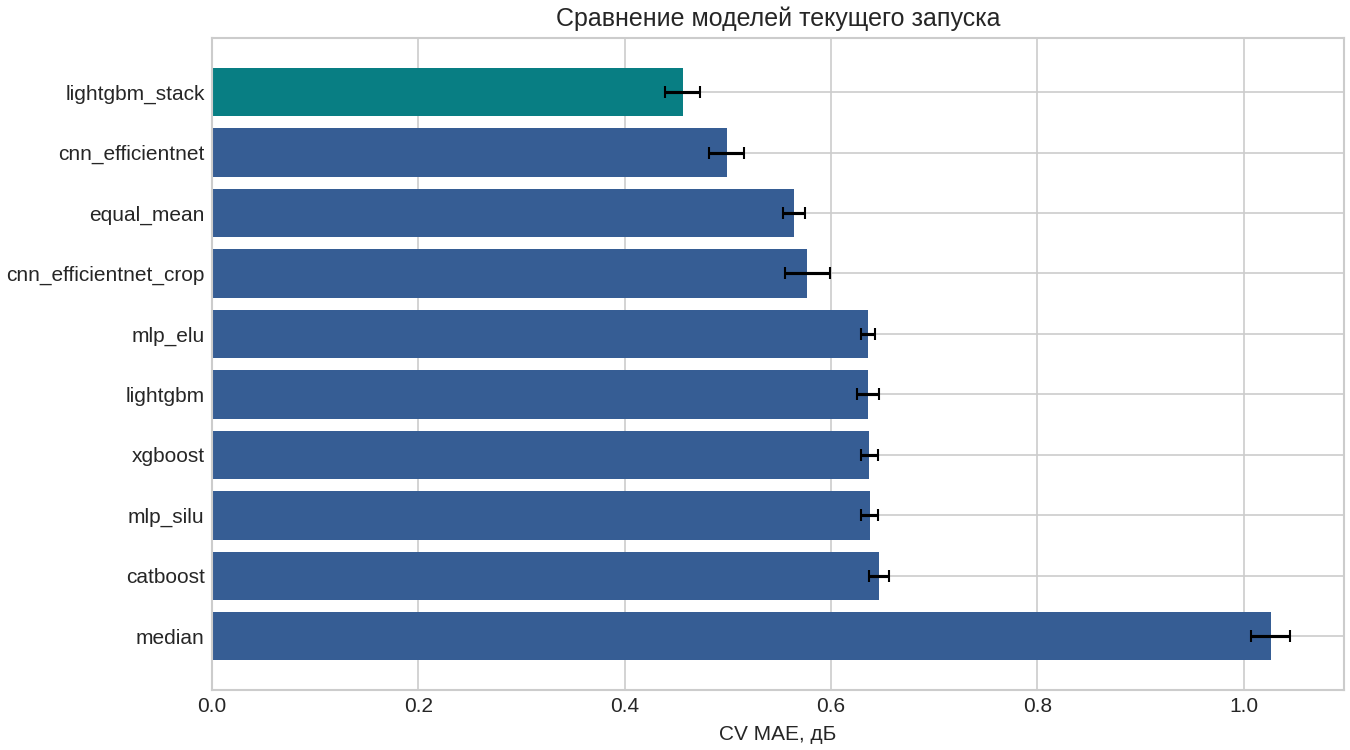

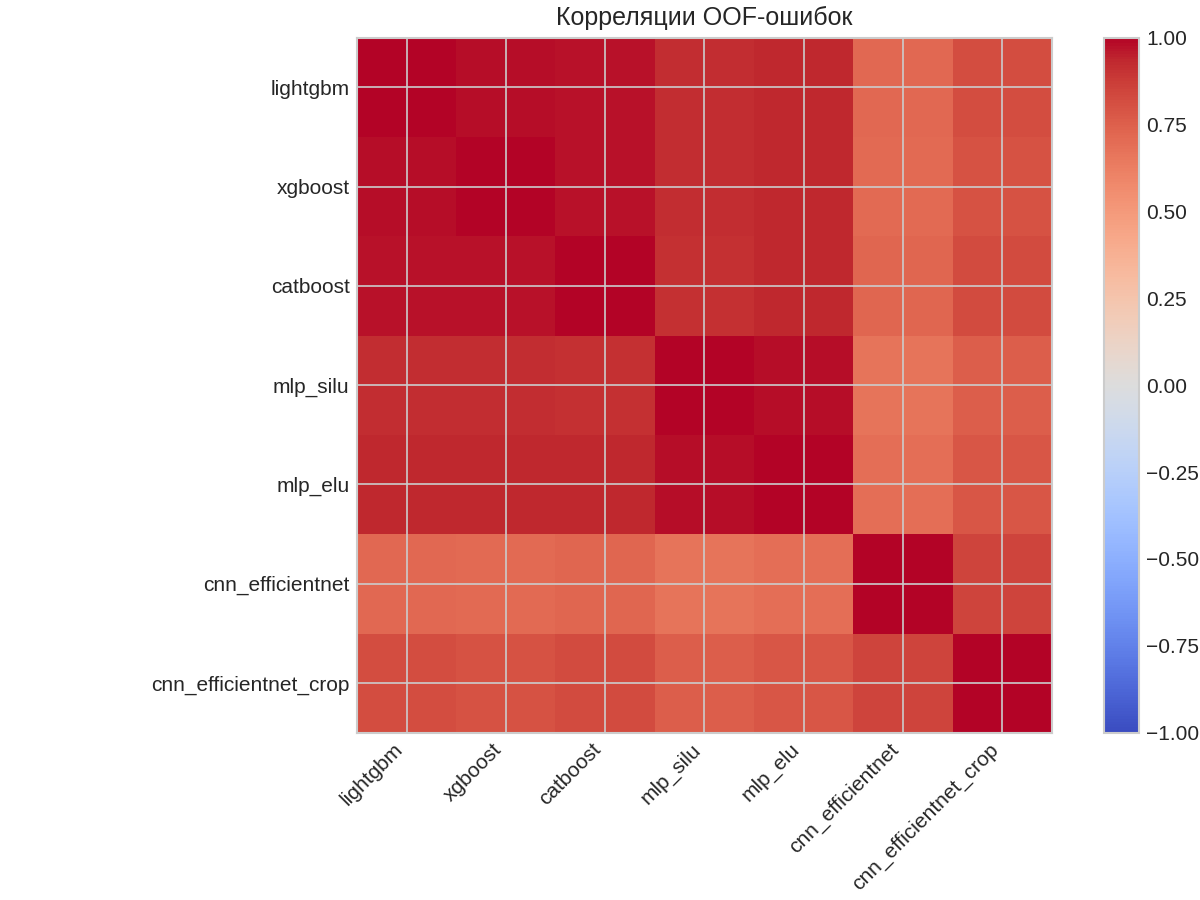

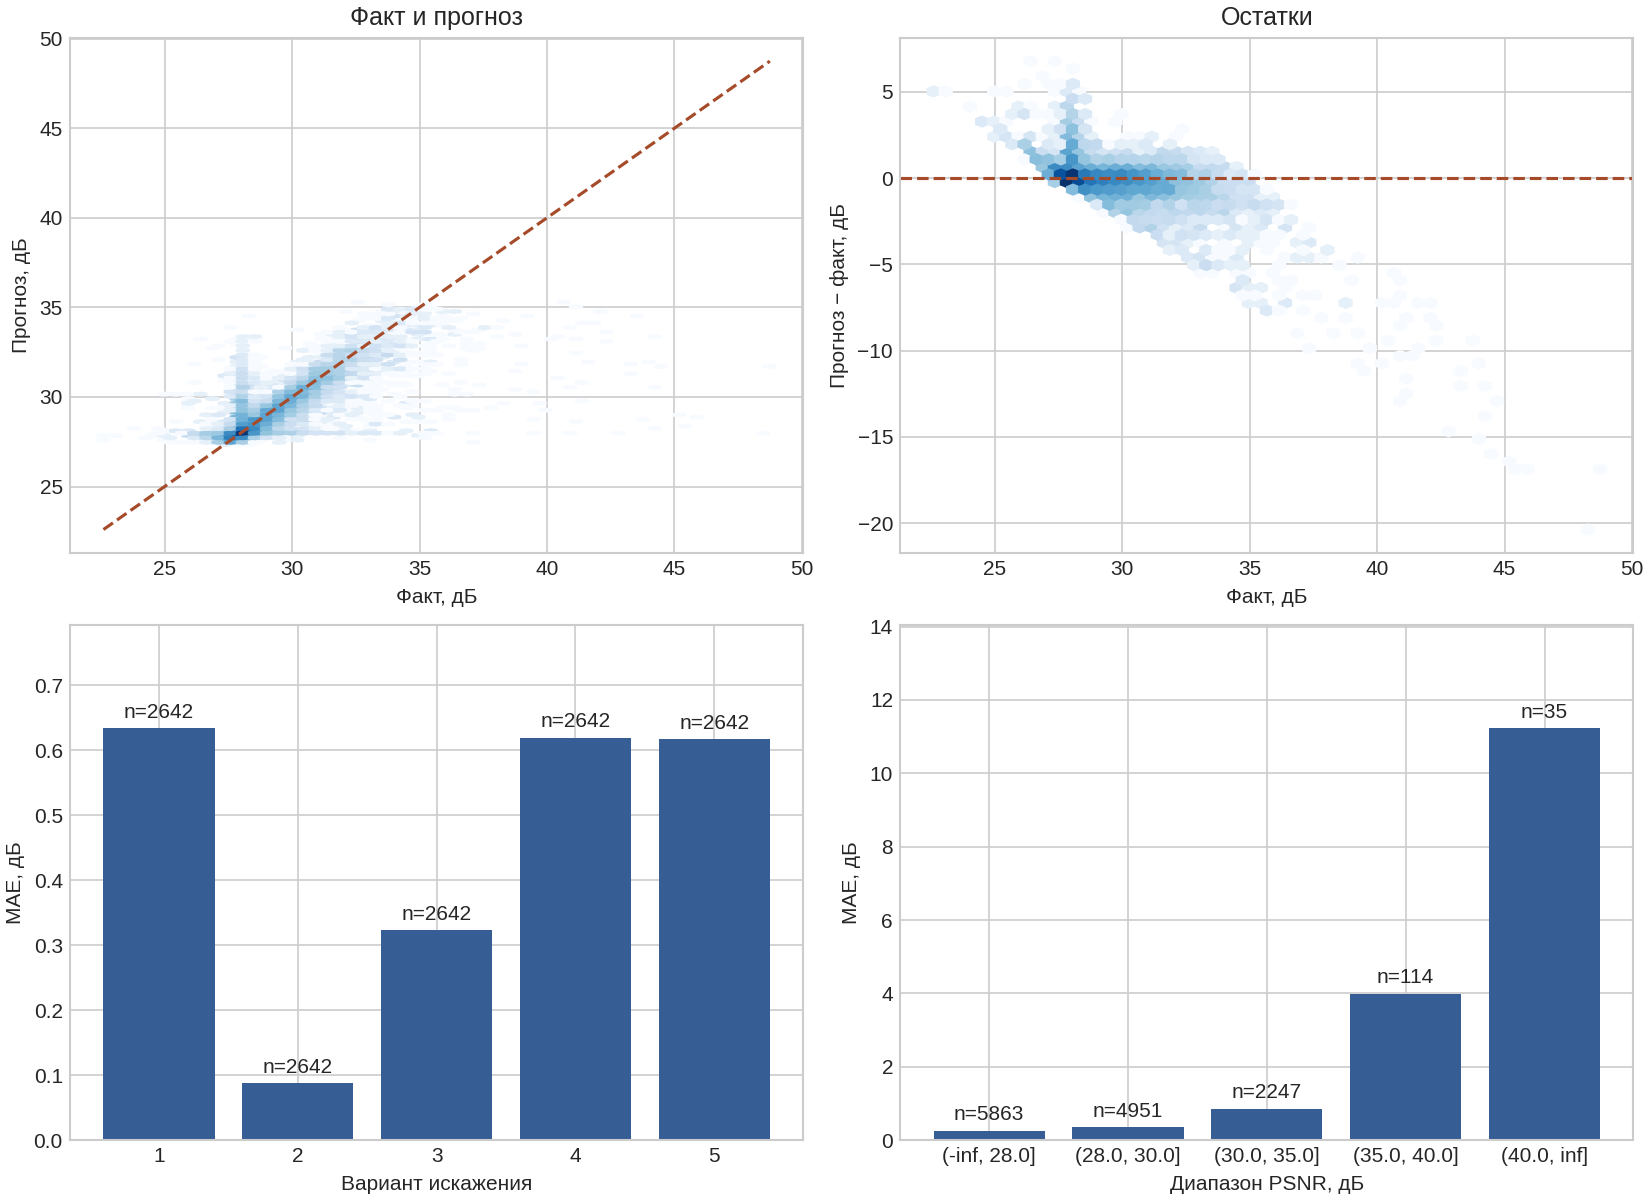

In [13]:
plt.style.use("seaborn-v0_8-whitegrid")
blue, teal = "#365d94", "#087e83"
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ordered = scores.sort_values("MAE", ascending=False)
ax.barh(ordered.index, ordered.MAE, xerr=ordered.fold_std, capsize=3,
        color=[teal if n == "lightgbm_stack" else blue for n in ordered.index])
ax.set(xlabel="CV MAE, дБ", title="Сравнение моделей текущего запуска")
fig.savefig(output / "01_models.png", dpi=150)
plt.show()

corr = base_oof.sub(target, axis=0).corr()
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
heatmap = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
ax.set_title("Корреляции OOF-ошибок")
fig.colorbar(heatmap, ax=ax)
fig.savefig(output / "02_correlation.png", dpi=150)
plt.show()

residual = stack_oof - target.to_numpy()
bins = pd.cut(target, [-np.inf, 28, 30, 35, 40, np.inf])
errors = pd.DataFrame({"error": np.abs(residual), "variant": train.variant, "range": bins})
fig, axes = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
ax = axes[0, 0]
ax.hexbin(target, stack_oof, gridsize=55, mincnt=1, bins="log", cmap="Blues")
limits = [min(target.min(), stack_oof.min()), max(target.max(), stack_oof.max())]
ax.plot(limits, limits, "--", color="#a64b2a")
ax.set(xlabel="Факт, дБ", ylabel="Прогноз, дБ", title="Факт и прогноз")
ax = axes[0, 1]
ax.hexbin(target, residual, gridsize=55, mincnt=1, bins="log", cmap="Blues")
ax.axhline(0, color="#a64b2a", linestyle="--")
ax.set(xlabel="Факт, дБ", ylabel="Прогноз − факт, дБ", title="Остатки")
groups = []
for ax, key, title in zip(axes[1], ("variant", "range"), ("Вариант искажения", "Диапазон PSNR, дБ")):
    stats = errors.groupby(key, observed=True).error.agg(mae="mean", n="size")
    bars = ax.bar(stats.index.astype(str), stats.mae, color=blue)
    ax.bar_label(bars, labels=[f"n={n}" for n in stats.n], padding=3)
    ax.set(xlabel=title, ylabel="MAE, дБ", ylim=(0, max(stats.mae.max() * 1.25, 0.01)))
    groups.append(stats.rename_axis("group").reset_index().assign(grouping=key))
pd.concat(groups, ignore_index=True).to_csv(output / "error_breakdown.csv", index=False)
fig.savefig(output / "03_errors.png", dpi=150)
plt.show()

## Файл для Kaggle

Колонки и порядок строк берутся из sample_submission.csv. В полном режиме итоговый файл содержит 3 310 строк. Сохранение CSV не отправляет его на оценку автоматически.

In [14]:
submission = test[["img_name"]].assign(PSNR=stack_test)
expected_ids = pd.read_csv(data_dir / "sample_submission.csv").img_name
if SMOKE:
    expected_ids = expected_ids.loc[expected_ids.isin(submission.img_name)].reset_index(drop=True)
assert submission.img_name.equals(expected_ids) and submission.img_name.is_unique
assert np.isfinite(submission.PSNR).all()
assert SMOKE or len(submission) == 3310
submission.to_csv(output / "submission.csv", index=False, lineterminator="\n")
print(f"{output / 'submission.csv'}: {len(submission)} строк")
display(submission.head())

/kaggle/working/psnr_solution/submission.csv: 3310 строк


,img_name,PSNR
0,100090_1.png,30.003640
1,100090_2.png,27.878991
2,100090_3.png,27.864564
3,100090_4.png,27.921505
4,100090_5.png,30.860402
